# Hands-on: Training a basic SST model with Anemoi

In this tutorial we will learn how to train an toy ML model to predict SST using the anemoi packages. Specifically, we will look at predicting SST from a 2 degree dataset, using SST and 2m air temperature at time t as input, to predict SST at time t + 1 day.

We will walk through some of the config choices in anemoi, and then run training on this simple model. There will then be the option to change some key parameters, and see how this impacts scores. By design the model is very simple, with a limited set of inputs and outputs, and small architecture. The focus isn't on predictive skill, but on learning to use anemoi to train ML models and make predictions, and exploring different design choices.

**Learning Objectives**
By the end of this tutorial, you will:
- Run a simple ML model to predict ocean SST one day ahead.
- Learn how to configure the anemoi training pipeline and make some simple changes
- Gain understanding of some key parameters

**Resources**
- [Anemoi Documentation](https://anemoi.readthedocs.io/projects/training/en/latest/)

## Setup

In [1]:
#ensure in the right dir if not already
current_dir = %pwd
if not (current_dir.endswith("ToySSTProblem") or current_dir.endswith("app")):
    %cd ToySSTProblem
%pwd

'/etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem'

We need to ensure we are working in a suitable environment. To enable this we have provided a requirements.txt file. This requires **python 3.12** — other Python versions (e.g. 3.11) may work but are not tested and may encounter package compatibility issues. To set your environment up, first load this version of python.

To keep things portable and avoid conflicts with other packages installed on your system, the cell below creates a dedicated virtual environment (`.venv-toysst`) and installs the required libraries into it, rather than into your user/global site-packages. Set `do_install` to `True` and run the cell below.

**Note:** after installation you need to select the **ToySST (.venv-toysst)** kernel from the kernel picker (top right of the notebook) and restart before continuing.

In [2]:
# Set 'do_install' to False to skip installation (e.g. if already done in a Docker container).
# Set 'do_install' to True to create/populate the dedicated virtual environment.

import os
import shutil
import subprocess
import sys
from pathlib import Path

do_install = True  # Set to True to install/update requirements

venv_dir = Path.cwd() / ".venv-toysst"
venv_python = venv_dir / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
pip_tmp_dir = Path.cwd() / ".pip_tmp"
pip_env = os.environ.copy()
pip_env["TMPDIR"] = str(pip_tmp_dir)

if do_install:
    pip_tmp_dir.mkdir(exist_ok=True)
    try:
        if not venv_dir.exists():
            print(f"Creating virtual environment at {venv_dir}")
            subprocess.check_call([sys.executable, "-m", "venv", str(venv_dir)])

        # These optional native extensions are not required; Anemoi uses its portable fallback.
        subprocess.call([
            str(venv_python), "-m", "pip", "uninstall", "-y",
            "torch-cluster", "torch-scatter", "torch-sparse",
        ], env=pip_env)

        pip = [str(venv_python), "-m", "pip", "install", "--no-cache-dir"]
        subprocess.check_call([*pip, "--upgrade", "pip"], env=pip_env)
        subprocess.check_call([*pip, "-r", "requirements.txt"], env=pip_env)
        subprocess.check_call([*pip, "ipykernel"], env=pip_env)
        subprocess.check_call([
            str(venv_python), "-m", "ipykernel", "install",
            "--user", "--name", "toysst", "--display-name", "ToySST (.venv-toysst)",
        ])
    finally:
        shutil.rmtree(pip_tmp_dir, ignore_errors=True)

    print('')
    print("*" * 97)
    print("Installation complete. Select the 'ToySST (.venv-toysst)' kernel from the kernel picker, then restart before continuing.")
    print("*" * 97)

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
INFO: pip 

In [1]:
# Import the necessary modules
import warnings
from tqdm import TqdmWarning
warnings.filterwarnings(
    "ignore",
    message="IProgress not found. Please update jupyter and ipywidgets."
)

import torch

import yaml
from omegaconf import OmegaConf
from pathlib import Path

import shutil
import os
import sys
import subprocess
from IPython.display import display, Image

# Load our minimal configuration file
config_path = Path("./training_configs/ToySST.yaml")
with open(config_path, 'r') as f:
    config = yaml.safe_load(f)

import mlflow
import pandas as pd
import matplotlib.pyplot as plt

import zarr, s3fs
from tqdm import tqdm

%matplotlib inline


#### Obtain data

A data.zarr file and a tarball with output from a pre-trained model are available on S3 cloud storage. The cell below pulls this data.

In [2]:
## First pull the output from a pre-trained model, and change permissions.
## This should create a directory "pretrained_outputs" containing checkpoints, logs and plots
%pwd
if Path("../pretrained_outputs_v2.tgz").exists():
    print("pretrained data exists")
else:
    print("Downloading pretrained outputs")
    !curl -L https://object-store.os-api.cci1.ecmwf.int/ecmwf-training-nwp-ml/pretrained_outputs_v2.tgz | tar xz -C ..


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  884M  100  884M    0     0  80.4M      0  0:00:11  0:00:11 --:--:-- 86.6M


In [3]:
# Next pull the dataset in zarr format. This will create a file called ToySSTDataset.zarr

class ProgressStore:
    def __init__(self, store, pbar):
        self.store = store
        self.pbar = pbar

    def __getitem__(self, key):
        value = self.store[key]
        self.pbar.update(1)  # update per chunk
        return value

    def keys(self):
        return self.store.keys()

    def __iter__(self):
        return iter(self.store)

    def __len__(self):
        return len(self.store)

    def __contains__(self, key):
        return key in self.store


if Path("../ToySSTDataset.zarr").exists():
    print("dataset zarr file exists")
else:
    print("Downloading dataset zarr file")

    s3 = s3fs.S3FileSystem(
        anon=True,
        client_kwargs={"endpoint_url": "https://object-store.os-api.cci1.ecmwf.int"}
    )

    store = s3fs.S3Map(
        root="s3://ecmwf-training-nwp-ml/ToySSTDataset.zarr",
        s3=s3,
        check=False
    )

    local_store = zarr.DirectoryStore("../ToySSTDataset.zarr")

    total = len(store)  # number of chunks/files

    with tqdm(total=total, desc="Copying Zarr dataset") as pbar:
        wrapped_store = ProgressStore(store, pbar)
        zarr.copy_store(wrapped_store, local_store, if_exists="replace")

    print("✅ Dataset copied to ../ToySSTDataset.zarr")


Copying Zarr dataset: 100%|██████████| 1864/1864 [01:36<00:00, 19.25it/s]

✅ Dataset copied to ../ToySSTDataset.zarr


#### Check if using a GPU
The notebook will run on CPU, but will be very slow (6-12 hours or more). If you have access to GPU resource this is highly recommended (this reduces run time to ~10 minutes).

In [4]:
import torch
print("GPU:" if torch.cuda.is_available() else "CPU", 
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

GPU: NVIDIA A100-SXM4-40GB


## Building Our Training Config

We'll work in this notebook, first examining our training configuration, highlighting some key elements. 

The configs set up can be found in the directory training_configs. This is a collection of configuration files defining defaults for various top-level choices, along with a main config file, ToySST.yaml, which defines what is actually used.

We'll load this file and examine it section by section. This configration is combined with the defaults in the training_configs directory, to create the model and training set up. 

### 1: Default Configurations

The top-level decisions around training strategy and model design etc are all set in the defaults at the start of the config file. This is where we make decisions such as which architecture to use, and which training strategy to use (i.e. deterministic prediction which is the default or and ensemble set up, an autoencoder etc). 
- **Model architecture**: gnn, graphtransformer, transformer
- **Graph**: hierarchical, multi scale, ...
- **Training method**: single, ensemble, diffusion, tendency diffusion.

Here we see the defaults chosen for a Toy SST example.


In [5]:
# Display the default configuration section
print("Default Configurations:")
print("=" * 50)
print(yaml.dump(config['defaults'], default_flow_style=False))

Default Configurations:
- data: zarr
- dataloader: native_grid
- diagnostics: evaluation
- system: example
- graph: multi_scale
- model: graphtransformer
- task: forecaster
- training: single
- _self_



Here we have chosen to use the `zarr` and `native_grid` options for data and dataloader, the standard `evaluation` diagnostics (other options include e.g. ensemble evaluation) a `graph_transformer` architecture, with the `multi_scale` graph, and the `single` training option (this is designed for training a deterministic predictive model).

### Amendments to the default configuration files

Once these broad decisions are defined, the detailed choices are inhereted from the various yaml files within the training_configs directory. Specific changes to these defaults can be listed in the ToySST.yaml file to overwrite the inhereted options. Here we look at the amendments used for our toy SST example. (Bear in mind the defaults in anemoi relate, in most cases, to medium range weather forecast applications)

### 2: System Configuration

The system configuration defines decisions around hardware options, such as the number of GPUs being used and how to distrubute these, inputs (with their full paths) and the location for outputs.

In [17]:
# Display the system configuration section
print("System Configuration:")
print("=" * 50)
print(yaml.dump(config['system'], default_flow_style=False))


System Configuration:
hardware:
  accelerator: auto
  num_gpus_per_model: 1
  num_gpus_per_node: 1
  num_nodes: 1
input:
  dataset: ../ToySSTDataset.zarr
  graph: graph_n48.pt
output:
  root: ./new_training_outputs



### 3: Task Configuration
Having earlier taken the 'forecasting task' defaults, here we specify details, such as the time step being used for forecasts.

In [18]:
# Display the system configuration section
print("Task Configuration:")
print("=" * 50)
print(yaml.dump(config['task'], default_flow_style=False))

Task Configuration:
timestep: 24H



### 4: Data Configuration

The data configuration controls how variables are used during training and prediction. It specifies whether each variable is **forcing** (input only), **prognostic** (input and output), or **diagnostic** (output only), and also defines preprocessing/postprocessing choices such as what method to use for normalisation, and whether to replace Nans with alternative values.

> ⚠️ **Warning:** In this notebook (and in anemoi more generally), **forcing** is **not** used in the traditional ocean-modelling sense. Here, it simply means any input-only field, including static fields such as bathymetry or land–sea mask (although these are not used in this toy example).

In [19]:
# Display the data configuration section
print("Data Configuration:")
print("=" * 50)
print(yaml.dump(config['data'], default_flow_style=False))


Data Configuration:
datasets:
  data:
    const_imputer:
      0:
      - sst
    diagnostic: []
    forcing:
    - cos_latitude
    - cos_longitude
    - sin_latitude
    - sin_longitude
    - cos_julian_day
    - cos_local_time
    - sin_julian_day
    - sin_local_time
    - insolation
    - 2t
    normalizer:
      default: mean-std
      none:
      - cos_latitude
      - cos_longitude
      - sin_latitude
      - sin_longitude
      - cos_julian_day
      - cos_local_time
      - sin_julian_day
      - sin_local_time
      - insolation
    processors:
      const_imputer:
        _target_: anemoi.models.preprocessing.imputer.ConstantImputer
        config: ${data.datasets.data.const_imputer}
      normalizer:
        _target_: anemoi.models.preprocessing.normalizer.InputNormalizer
        config: ${data.datasets.data.normalizer}
frequency: 24h




The treatment of NaNs is defined here by imputing (filling nan values) with 0.

We define a number of variables which indicate the location, time of day and and time of year as forcing, along with 2 metre air temperature (2mT). There are no diagnostic (output only variables). All other variables are automatically defined as prognostic.

The way in which we nornalise data is defined. Setting the default as mean-std (so this is applied to any variables which aren't otherwise listed). No normalisation ('None') is specified for a few variables (chosen because their values already span 0 to 1).

Information about the the frequency at which to select data is given.

### 5: Dataloader Configuration

The dataloader defines what data to read in from the input files given in 'system', and how to read this in (batch sizes etc)


In [20]:
# Display the dataloader configuration section
print("Dataloader Configuration:")
print("=" * 50)
print(yaml.dump(config['dataloader'], default_flow_style=False))


Dataloader Configuration:
batch_size:
  test: 1
  training: 1
  validation: 1
dataset:
- dataset: ${system.input.dataset}
  end: 2024
  frequency: ${data.frequency}
  select:
  - 2t
  - sst
  - cos_julian_day
  - sin_julian_day
  - cos_local_time
  - sin_local_time
  - cos_longitude
  - sin_longitude
  - cos_latitude
  - sin_latitude
  - insolation
  start: 2020
limit_batches:
  training: 100
  validation: 25
num_workers:
  test: 1
  training: 1
  validation: 1
pin_memory: false
test:
  datasets:
    data:
      dataset_config:
        dataset: ${dataloader.dataset}
        frequency: ${data.frequency}
      end: 2024
      start: 2024
training:
  datasets:
    data:
      dataset_config:
        dataset: ${dataloader.dataset}
        frequency: ${data.frequency}
      end: 2022
      start: 2020
validation:
  datasets:
    data:
      dataset_config:
        dataset: ${dataloader.dataset}
        frequency: ${data.frequency}
      end: 2023
      start: 2023



For our toy example, we use batches of size 1.

We read in data from 2020 to 2024. Taking 2t (2m air temperature) from the atmospheric forcings dataset, and taking SST (avg_thetao_1), and various other inputs relating to location, timing etc, from the ocean dataset. 

We limit the model to just 100 batches per epoch (this is for computational speed for this toy example), with a smaller batch size of 25 used to calculate valdiation scores.

The data is split as follows:
- Training period: 2020-2022
- Validation period: 2023
- Test period: 2024

### 6: Graph Configuration

The choice of graph, and whether this is used just for the encoder & decoder, or also used as the processor is defined in the default choices at the top.

Local changes generally include things like the graph shape and resolution

In [21]:
# Display the graph configuration section
print("Graph Configuration:")
print("=" * 50)
print(yaml.dump(config['graph'], default_flow_style=False))


Graph Configuration:
nodes:
  hidden:
    node_builder:
      resolution: 4



Here we change the resolution to 4, giving us a fairly coarse grid, as we are using coarse data for this toy example.

### 7: Model Configuration

Again the main decisions around the model (the architecture etc) are defined by the choice of model in the default configurations.

Local amendments often include the number of channels (i.e. the size and complexity of the model)

In [22]:
# Display the model configuration section
print("Model Configuration:")
print("=" * 50)
print(yaml.dump(config['model'], default_flow_style=False))


Model Configuration:
bounding:
  datasets:
    data: []
compile: []
num_channels: 128



Here we define a relatively small number of channels for this toy problem, otherwise we take the default options for the graphtransformer model.

In this example we specify no bounding. Bounding can be used to try and learn physcial limits, such as ocean temperature remaining above freezing. 

### 8: Training 

Here we define things about _how_ the model is trained. We configure the training parameters, strategy, and loss function used for training. 

In [23]:
# Display the training configuration section
print("Training Configuration:")
print("=" * 50)
print(yaml.dump(config['training'], default_flow_style=False))


Training Configuration:
max_epochs: 10
max_steps: 500
metrics:
  datasets:
    data:
    - sst
optimization:
  lr: 5e-4
  lr_scheduler:
    lr_min: 3e-7
    warmup_t: 10
training_loss:
  datasets:
    data:
      _target_: anemoi.training.losses.MSELoss
      ignore_nans: true
      scalers:
      - nan_mask_weights
      - node_weights



Here the learning rate starts at `3e-7` and is linearly warmed up over `10` steps to the target learning rate.  After warmup, it follows a **CosineLRScheduler** ([implementation](https://github.com/huggingface/pytorch-image-models/blob/main/timm/scheduler/cosine_lr.py#L19), [ref](https://arxiv.org/pdf/1608.03983)) decay toward the minimum learning rate.

Metrics are calculated on the SST variable, avg_thetao_1.

The mean square error (`MSELoss`) loss is used here. We ignore NaNs, so points which were originally NaNs (i.e the land in this ocean example) are not included in the loss. We also scale the loss based on different scalers:
- `node_weights`: Weights each node’s contribution to the loss according to the physical area represented by that graph node, so nodes covering larger regions have a proportionally larger influence on the total loss.
- `general_variable` (not specified): Applies a separate scaling factor to each variable, allowing variables with different magnitudes or priorities to contribute in a balanced way.
- `vertical_level` (not specified): Applies separate scaling factors by vertical level, so errors at different depths can be weighted differently in the total loss.

### 9: Diagnostics Configuration

Here we define what diagnostics will be carried out. Decisions around where to log metrics and what metrics to log are included here.

In [24]:
# Display the diagnostics configuration section
print("Diagnostics Configuration:")
print("=" * 50)
print(yaml.dump(config['diagnostics'], default_flow_style=False))


Diagnostics Configuration:
log:
  mlflow:
    authentication: true
    enabled: true
    experiment_name: ToySST
    offline: true
    run_name: testing_1
    tracking_uri: file:${system.output.root}/logs/mlflow
plot:
  asynchronous: false
  callbacks:
  - _target_: anemoi.training.diagnostics.callbacks.plot.LossCurvePlot
    dataset_names:
    - data
    parameter_groups:
      surface_ocean:
      - sst
  - _target_: anemoi.training.diagnostics.callbacks.plot.BatchOutputPlot
    dataset_names:
    - data
    parameters: ${diagnostics.plot.parameters}
    plot_fn:
      _partial_: true
      _target_: anemoi.training.diagnostics.evaluation.plotting.batch_output.sample_plot_fn
      accumulation_levels_plot:
      - 0
      - 0.05
      - 0.1
      - 0.25
      - 0.5
      - 1
      - 1.5
      - 2
      - 3
      - 4
      - 5
      - 6
      - 7
      - 100
      colormaps: ${diagnostics.plot.settings.colormaps}
      per_sample: 6
    sample_idx: ${diagnostics.plot.sample_idx}
    t

The first set of lines describes how to log the data, here we log to mlflow, with an experiment name 'ToySST', and a run name 'testing_1'. When developing models, multiple runs can be logged under the ToySST experiment name for easy comparison.

We then define the plots to produce. Here we first ask for plots of the loss over training, for the SST parameter (here this is the only predicted variable, but in other applications you can group sets of variables, i.e. all surface variables can form a group). We also ask for plots of sample predictions, again specifying the SST to be the only plotted parameter.

## Training Execution

Now that we have our configuration ready, let's execute the training. We'll run a short training session to verify everything works correctly. First we set the base seed:

```bash
export ANEMOI_BASE_SEED=42
```

We then pass the configuration directory explicitly:

```bash
python -m anemoi.training train \
    --config-path="$PWD/training_configs" \
    --config-name=ToySST
```

The cell below runs the equivalent command using the active notebook kernel.

In [13]:
cfg_dir = (Path.cwd() / "training_configs").resolve()

# Set environment variables
os.environ['ANEMOI_BASE_SEED'] = '42'
os.environ['POSSIBLE_USER_WARNINGS'] = 'off'
os.environ['TORCH_LOGS'] = "-dynamo,-inductor"
os.environ['HYDRA_FULL_ERROR'] = '1'
os.environ['MPLBACKEND'] = 'Agg'  # Use non-interactive backend in training subprocess to avoid IPython circular import
os.environ['MLFLOW_ALLOW_FILE_STORE'] = 'true'

# Execute the training using subprocess
print("Starting ML-ocean training...")
print(f"Config directory: {cfg_dir}")
print("=" * 50)

process = subprocess.Popen(
    [
        sys.executable, "-m", "anemoi.training", "train",
        f"--config-path={cfg_dir}",
        "--config-name=ToySST",
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,  # Merge stderr into stdout
    text=True,
    bufsize=1,
)

# Stream output
for line in iter(process.stdout.readline, ''):
    if line:
        print(line.rstrip())

# Wait for completion
return_code = process.wait()

print("=" * 50)
if return_code == 0:
    print("Training completed successfully!")
else:
    print(f"Training failed with return code {return_code}")

Starting ML-ocean training...
Config directory: /etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem/training_configs
2026-09-29 16:49:14 INFO Running anemoi training command with overrides: ['--config-path=/etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem/training_configs', '--config-name=ToySST']
2026-09-29 16:49:23 INFO Appending current working directory (/etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem) to the search path.
2026-09-29 16:49:23 INFO Search path is now: [provider=hydra, path=pkg://hydra.conf, provider=main, path=/etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem/training_configs, provider=anemoi-cwd-searchpath-plugin, path=/etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem, provider=anemoi-package-searchpath-plugin, path=pkg://anemoi.training/config]
/etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem/.venv-toysst/lib64/python3.12/site-packages/torch/__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precisio

## Monitoring and Results

### MLflow logging

Several metrics and parameters are logged during training. Here, we access metrics calculated by MLflow during the model training, and use these to assess performance.

We can create plots of key metrics during training, here we look at:
- **Training Loss**: The loss should decrease over time, and indicates if the model is learning to fit the data.
- **Validation Metrics**: Similar to training loss, but calculated on validation data, these results indicate if there is any overfitting.

*Note:* Logging can be done 'online' during training, with results logged to a server and can then be viewed interactively on a website.

Here we set the "Run id" for a pre-trained model (the data we pulled form S3 earlier), to analyse the expected outputs.

First we open the mlflow logs, and print which metrics are available.

In [25]:
# Set the runId for the run you'd like to investigate.
run_id = "2ece55884e0a415d83e8a96ddfec351b"

# Connect to the local MLflow tracking server (here a local directory) used by anemoi-training
tracking_uri = f"file://{os.getcwd()}/../pretrained_outputs/logs/mlflow"
print(tracking_uri)
client = mlflow.tracking.MlflowClient(tracking_uri=tracking_uri)

run = client.get_run(run_id)
print(f"Run name : {run.info.run_name}")
print(f"Run ID   : {run_id}")
print(f"\nAvailable metrics:")
for k in sorted(run.data.metrics.keys()):
    print(f"  {k}")


file:///etc/ecmwf/nfs/dh1_home_a/ecm4259/ToySSTProblem/../pretrained_outputs/logs/mlflow
Run name : testing
Run ID   : 2ece55884e0a415d83e8a96ddfec351b

Available metrics:
  epoch
  lr-AdamW
  rollout
  train_multi_dataset_loss_epoch
  train_multi_dataset_loss_step
  val_data_lossvariablemapper_loss
  val_data_mse_metric/data/all/1
  val_data_mse_metric/data/sfc_sst/1
  val_data_mse_metric/data/sst/1
  val_multi_dataset_loss_epoch
  val_multi_dataset_loss_step


We then select the training and validation loss per epoch, and produce a line plot showing how these change over the very short training run completed above.

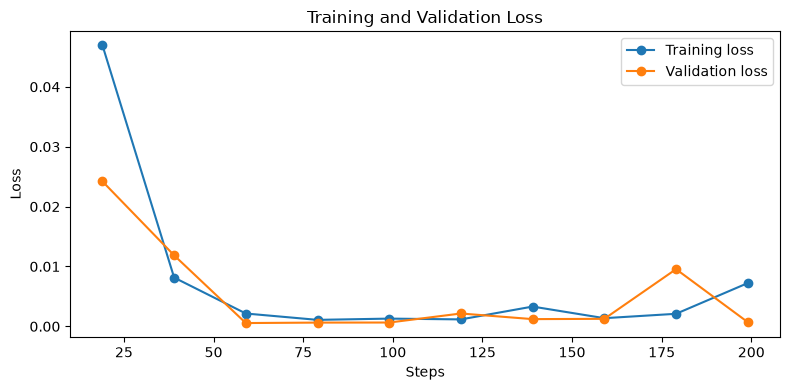

In [26]:
# Fetch the training and validation loss recorded each epoch
metric_names = ["train_multi_dataset_loss_epoch", "val_multi_dataset_loss_epoch"]

records = []
for metric in metric_names:
    for entry in client.get_metric_history(run_id, metric):
        records.append({"metric": metric, "epoch": entry.step, "loss": entry.value})

df = pd.DataFrame(records)
if df.empty:
    raise ValueError(f"No loss metrics found for run {run_id} (status: {client.get_run(run_id).info.status}). Check the run_id points to a completed training run.")

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
for metric, label in zip(metric_names, ["Training loss", "Validation loss"]):
    subset = df[df["metric"] == metric].sort_values("epoch")
    ax.plot(subset["epoch"], subset["loss"], "-o", label=label)

ax.set_xlabel("Steps")
ax.set_ylabel("Loss")
ax.set_title("Training and Validation Loss")
ax.legend()
plt.tight_layout()
plt.show()


### Task 1: Change some key training variables and investigate the impact on scores the learning rate, number of channels, and max_epochs

First recreate the plots above with data from your own training runs. You will need to replace the run_id with the value in the output from your training run. This is printed around line 18 of the output, look for `Run id:`.

(Note we have also changed `tracking_uri` to `f"file://{os.getcwd()}/new_training_outputs/logs/mlflow"`, you do not need to change this again if looking at your own runs)


In [27]:
# Set the runId for the run you'd like to investigate.
run_id = '6838eb67fbdf4e7fabdf44dfa5197720'

# Connect to the local MLflow tracking server (here a local directory) used by anemoi-training
tracking_uri = f"file://{os.getcwd()}/new_training_outputs/logs/mlflow"

client = mlflow.tracking.MlflowClient(tracking_uri=tracking_uri)

run = client.get_run(run_id)
print(f"Run name : {run.info.run_name}")
print(f"Run ID   : {run_id}")
print(f"\nAvailable metrics:")
for k in sorted(run.data.metrics.keys()):
    print(f"  {k}")


Run name : testing_1
Run ID   : 6838eb67fbdf4e7fabdf44dfa5197720

Available metrics:
  epoch
  lr-AdamW
  rollout
  train_multi_dataset_loss_epoch
  train_multi_dataset_loss_step
  val_data_lossvariablemapper_loss
  val_data_mse_metric/data/all/1
  val_data_mse_metric/data/sfc_sst/1
  val_data_mse_metric/data/sst/1
  val_multi_dataset_loss_epoch
  val_multi_dataset_loss_step


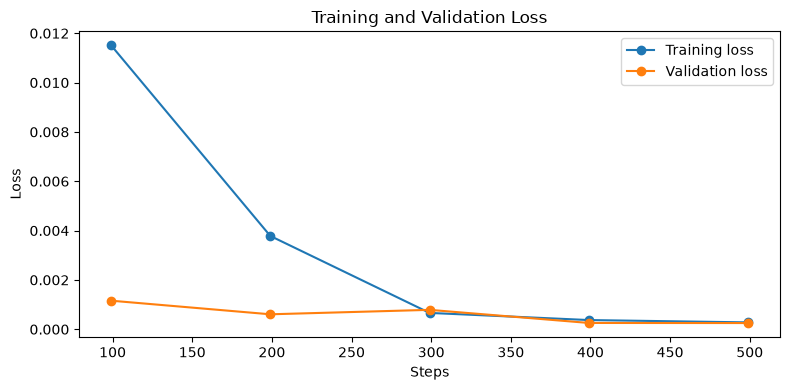

In [28]:

# Fetch the training and validation loss recorded each epoch
metric_names = ["train_multi_dataset_loss_epoch", "val_multi_dataset_loss_epoch"]

records = []
for metric in metric_names:
    for entry in client.get_metric_history(run_id, metric):
        records.append({"metric": metric, "epoch": entry.step, "loss": entry.value})

df = pd.DataFrame(records)
if df.empty:
    raise ValueError(f"No loss metrics found for run {run_id} (status: {client.get_run(run_id).info.status}). Check the run_id points to a completed training run.")

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
for metric, label in zip(metric_names, ["Training loss", "Validation loss"]):
    subset = df[df["metric"] == metric].sort_values("epoch")
    ax.plot(subset["epoch"], subset["loss"], "-o", label=label)

ax.set_xlabel("Steps")
ax.set_ylabel("Loss")
ax.set_title("Training and Validation Loss")
ax.legend()
plt.tight_layout()
plt.show()


Next, adapt the training config (by directly editing the file ToySST.yaml in the training_configs directory) and retrain the model with any of the following (or your own ideas!). You can then plot some of the metrics from these runs by changing the run_id again, as discussed above, and see what impact your changes have on the training and validation loss:
   - Increase the number of samples considered within each training epoch, by increasing `data_loader: limit_batches: training` (note this will increase run times, but should improve model performance)
   - Train the model for longer by increasing the number of iterations (`max_epochs` and/or `max_steps`)
   - Amend the size of the model, by increasing or decreasing the number of channels (`num_channels`)
   - Double or half the learning rate (`training: lr: rate`)

**Questions**
- How does your loss change with these adaptions? 
- How much longer does the training take (per iteration and/or in total)?
- Does the relationshop between training and validation loss change? Are there any signs of overfitting? (you may need to carry out longer runs to be able to assess this)

***Note***:

You do not need to do the training in the notebook. Once the ToySST.yaml file has been edited, you can either rerun the training cell of the notebook, or you can run directly on the console with: 
```
anemoi-training train --config-path=PATH-TO-YOUR-CONFIG-FOLDER --config-name=ToySST
```

#### For a slightly more complex change
   - Remove the 2m temperature forcing field from the model (hint, you will need to consider both the `data` and `dataloader` parts of the configuration).
   How does this impact the training and validation scores?


### Inference of your model

Training is about letting the model learn the optimal set of weights to make predictions. Once these are learned, we can use the trained model to make predictions, this is referred to as inference.

To run inference on a pretrained model based on the above, go to the Jupyter notebook `inference_ToySST.ipynb`. Here you can also test running inference on the models you've trained yourselves.

